In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from pathlib import Path


In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
ANNOTATIONS_DIR = DATA_DIR / "annotations"
RAW_DIR = DATA_DIR / "raw"
ATTR_PATH = ANNOTATIONS_DIR / "list_attr_celeba.txt"

for path in (ATTR_PATH, ANNOTATIONS_DIR / "identity_CelebA.txt", RAW_DIR):
    if not path.exists():
        raise FileNotFoundError(f"Не найден путь: {path}")
print("Корень проекта:", PROJECT_ROOT)

Корень проекта: C:\Users\User\Desktop\face-recognition


In [3]:
attrs = pd.read_csv(
    ATTR_PATH,
    sep=r"\s+",
    skiprows=1,
    index_col=0
)

print(attrs.shape)
print(attrs.head())

(202599, 40)
            5_o_Clock_Shadow  Arched_Eyebrows  Attractive  Bags_Under_Eyes  \
000001.jpg                -1                1           1               -1   
000002.jpg                -1               -1          -1                1   
000003.jpg                -1               -1          -1               -1   
000004.jpg                -1               -1           1               -1   
000005.jpg                -1                1           1               -1   

            Bald  Bangs  Big_Lips  Big_Nose  Black_Hair  Blond_Hair  ...  \
000001.jpg    -1     -1        -1        -1          -1          -1  ...   
000002.jpg    -1     -1        -1         1          -1          -1  ...   
000003.jpg    -1     -1         1        -1          -1          -1  ...   
000004.jpg    -1     -1        -1        -1          -1          -1  ...   
000005.jpg    -1     -1         1        -1          -1          -1  ...   

            Sideburns  Smiling  Straight_Hair  Wavy_Hair  Wea

In [4]:
print(attrs.columns.tolist())
print(attrs.loc["000001.jpg"])

['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young']
5_o_Clock_Shadow      -1
Arched_Eyebrows        1
Attractive             1
Bags_Under_Eyes       -1
Bald                  -1
Bangs                 -1
Big_Lips              -1
Big_Nose              -1
Black_Hair            -1
Blond_Hair            -1
Blurry                -1
Brown_Hair             1
Bushy_Eyebrows        -1
Chubby                -1
Double_Chin           -1
Eyeglasses            -1
Goatee         

In [5]:
total = len(attrs)

smiling_count = (attrs["Smiling"] == 1).sum()
smiling_percentage = smiling_count/total * 100
print(f"Всего изображений: {total}" )
print(f'Улыбающихся: {smiling_count}')
print(f'Процент улыбающизся: {smiling_percentage:.2f}%')

Всего изображений: 202599
Улыбающихся: 97669
Процент улыбающизся: 48.21%


In [6]:
glasses_count = (attrs["Eyeglasses"] == 1).sum()
glasses_percentage = glasses_count/total * 100
print(f'C очками: {glasses_count}')
print(f'процент очкариков: {glasses_percentage:.2f}%')

C очками: 13193
процент очкариков: 6.51%


In [7]:
attribute_counts = (attrs == 1).sum()
print(attribute_counts)

5_o_Clock_Shadow        22516
Arched_Eyebrows         54090
Attractive             103833
Bags_Under_Eyes         41446
Bald                     4547
Bangs                   30709
Big_Lips                48785
Big_Nose                47516
Black_Hair              48472
Blond_Hair              29983
Blurry                  10312
Brown_Hair              41572
Bushy_Eyebrows          28803
Chubby                  11663
Double_Chin              9459
Eyeglasses              13193
Goatee                  12716
Gray_Hair                8499
Heavy_Makeup            78390
High_Cheekbones         92189
Male                    84434
Mouth_Slightly_Open     97942
Mustache                 8417
Narrow_Eyes             23329
No_Beard               169158
Oval_Face               57567
Pale_Skin                8701
Pointy_Nose             56210
Receding_Hairline       16163
Rosy_Cheeks             13315
Sideburns               11449
Smiling                 97669
Straight_Hair           42222
Wavy_Hair 

In [8]:
attribute_counts.sort_values().head(5)

Bald           4547
Mustache       8417
Gray_Hair      8499
Pale_Skin      8701
Double_Chin    9459
dtype: int64

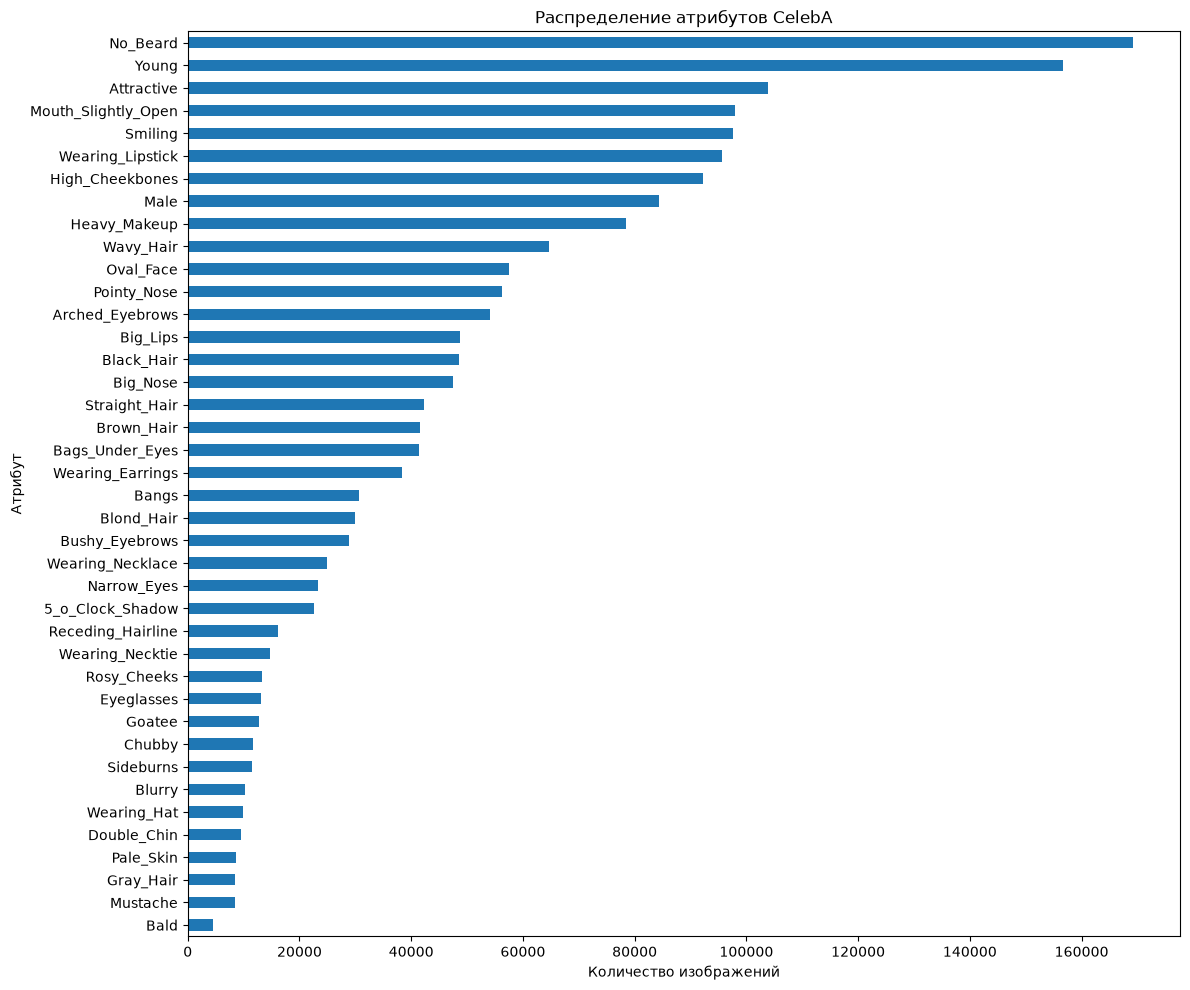

In [9]:
attribute_counts = attribute_counts.sort_values()
plt.figure(figsize=(12,10))
attribute_counts.plot(kind='barh')

plt.xlabel("Количество изображений")
plt.ylabel("Атрибут")
plt.title("Распределение атрибутов CelebA")

plt.tight_layout()
plt.show()


In [10]:
selected_attributes = [
    "Eyeglasses",
    "Smiling",
    "Pointy_Nose",
    "Wearing_Lipstick",
    "Mustache",
    "Bangs",
    "Mouth_Slightly_Open",
    "Narrow_Eyes"
]

selected_data = attrs[selected_attributes]

display(selected_data.head())

,Eyeglasses,Smiling,Pointy_Nose,Wearing_Lipstick,Mustache,Bangs,Mouth_Slightly_Open,Narrow_Eyes
000001.jpg,-1,1,1,1,-1,-1,1,-1
000002.jpg,-1,1,-1,-1,-1,-1,1,-1
000003.jpg,-1,-1,1,-1,-1,-1,-1,1
000004.jpg,-1,-1,1,1,-1,-1,-1,-1
000005.jpg,-1,-1,1,1,-1,-1,-1,1


In [11]:
attribute_percentages = (
    (selected_data == 1).mean() * 100
)

display(attribute_percentages.sort_values(ascending=False))

Mouth_Slightly_Open    48.342786
Smiling                48.208037
Wearing_Lipstick       47.243570
Pointy_Nose            27.744461
Bangs                  15.157528
Narrow_Eyes            11.514864
Eyeglasses              6.511878
Mustache                4.154512
dtype: float64

In [12]:
identity_path = ANNOTATIONS_DIR / "identity_CelebA.txt"

identities = pd.read_csv(
    identity_path,
    sep=r"\s+",
    header=None,
    names=["image_id", "identity_id"]
)

display(identities.head())

,image_id,identity_id
0,000001.jpg,2880
1,000002.jpg,2937
2,000003.jpg,8692
3,000004.jpg,5805
4,000005.jpg,9295


In [13]:
print(identities["identity_id"].nunique())

10177


In [14]:
attrs_reset = attrs.reset_index().rename(columns={attrs.index.name or "index": "image_id"})
df = attrs_reset.merge(identities, on="image_id", how="inner", validate="one_to_one")
assert len(df) == len(attrs), "Не все фотографии сопоставлены с identity_CelebA.txt"
print("Размер объединённой таблицы:", df.shape)
display(df.head())

Размер объединённой таблицы: (202599, 42)


,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young,identity_id
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,1,1,-1,1,-1,1,-1,-1,1,2880
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,1,-1,-1,-1,-1,-1,-1,-1,1,2937
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,1,-1,-1,-1,-1,-1,1,8692
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,1,-1,1,-1,1,1,-1,1,5805
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,1,-1,-1,1,9295


In [15]:
photos_per_person = df.groupby("identity_id").size()

display(photos_per_person.head(10))

identity_id
1     29
2      8
3     25
4     22
5     20
6     24
7     24
8     26
9      5
10    19
dtype: int64

In [16]:
photos_per_person.sort_values(ascending=False).head(10)

identity_id
2820    35
3227    35
3782    35
3699    34
3745    34
9152    32
9256    32
8968    32
9840    31
6568    31
dtype: int64

In [17]:
photos_per_person = df.groupby("identity_id").size()

display(photos_per_person.head(10))

identity_id
1     29
2      8
3     25
4     22
5     20
6     24
7     24
8     26
9      5
10    19
dtype: int64

In [18]:
photos_per_person.sort_values(ascending=False).head(10)

identity_id
2820    35
3227    35
3782    35
3699    34
3745    34
9152    32
9256    32
8968    32
9840    31
6568    31
dtype: int64

In [19]:
eligible_people = photos_per_person[photos_per_person >= 20]
print(f'Подходящих людей: {len(eligible_people)}')

Подходящих людей: 6348


In [20]:
eligible_ids = eligible_people.index

eligible_df = df[
    df["identity_id"].isin(eligible_ids)
]

print("Подходящих фотографий:", len(eligible_df))
print("Уникальных людей:", eligible_df["identity_id"].nunique())

Подходящих фотографий: 163749
Уникальных людей: 6348


In [21]:
# 1. Создаём комбинации атрибутов
data = eligible_df.copy()

data["stratum"] = (
    data[selected_attributes]
    .astype(str)
    .agg("_".join, axis=1)
)

# 2. Группируем фотографии по людям
person_groups = list(data.groupby("identity_id"))

# 3. Сортируем людей по количеству фотографий
person_groups.sort(
    key=lambda x: len(x[1]),
    reverse=True
)

# 4. Оставляем 500 человек
person_groups = person_groups[:500]

# 5. Выбираем 20 фотографий каждого человека
rng = np.random.default_rng(42)

selected_images = []

for person_id, group in person_groups:

    # Перемешиваем фотографии человека
    indices = rng.permutation(len(group))
    group = group.iloc[indices]

    # Сначала берём фотографии с разными комбинациями атрибутов
    diverse = group.drop_duplicates(subset="stratum")

    photos = diverse.iloc[:20]

    # Если фотографий меньше 20 — добираем оставшиеся
    if len(photos) < 20:

        remaining = group.drop(index=photos.index)

        extra = remaining.iloc[:20 - len(photos)]

        photos = pd.concat([photos, extra])

    selected_images.append(photos)

# 6. Объединяем всё в один DataFrame
selected_df = pd.concat(
    selected_images,
    ignore_index=True
)

print("Количество фотографий:", len(selected_df))
print("Количество людей:", selected_df["identity_id"].nunique())
print("Количество комбинаций:", selected_df["stratum"].nunique())

Количество фотографий: 10000
Количество людей: 500
Количество комбинаций: 130


In [22]:
comparison = pd.DataFrame({
    "CelebA (%)": (df[selected_attributes] == 1).mean() * 100,
    "Selected (%)": (selected_df[selected_attributes] == 1).mean() * 100
})

display(comparison.round(2))

,CelebA (%),Selected (%)
Eyeglasses,6.51,4.32
Smiling,48.21,47.03
Pointy_Nose,27.74,34.29
Wearing_Lipstick,47.24,50.74
Mustache,4.15,6.16
Bangs,15.16,18.90
Mouth_Slightly_Open,48.34,46.66
Narrow_Eyes,11.51,11.29


In [23]:
bbox_df = pd.read_csv(
    ANNOTATIONS_DIR / "list_bbox_celeba.txt",
    sep=r"\s+", skiprows=2, header=None,
    names=["image_id", "x_1", "y_1", "width", "height"]
)
assert bbox_df["image_id"].is_unique
print("Размер bbox:", bbox_df.shape)
display(bbox_df.head())

Размер bbox: (202599, 5)


,image_id,x_1,y_1,width,height
0,000001.jpg,95,71,226,313
1,000002.jpg,72,94,221,306
2,000003.jpg,216,59,91,126
3,000004.jpg,622,257,564,781
4,000005.jpg,236,109,120,166


In [24]:
landmark_columns = [
    "lefteye_x", "lefteye_y", "righteye_x", "righteye_y",
    "nose_x", "nose_y", "leftmouth_x", "leftmouth_y",
    "rightmouth_x", "rightmouth_y"
]
landmarks_df = pd.read_csv(
    ANNOTATIONS_DIR / "list_landmarks_celeba.txt",
    sep=r"\s+", skiprows=2, header=None,
    names=["image_id"] + landmark_columns
)
assert landmarks_df["image_id"].is_unique
print("Размер landmarks:", landmarks_df.shape)
display(landmarks_df.head())

Размер landmarks: (202599, 11)


,image_id,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,165,184,244,176,196,249,194,271,266,260
1,000002.jpg,140,204,220,204,168,254,146,289,226,289
2,000003.jpg,244,104,264,105,263,121,235,134,251,140
3,000004.jpg,796,539,984,539,930,687,762,756,915,756
4,000005.jpg,273,169,328,161,298,172,283,208,323,207


In [25]:
selected_df = (
    selected_df
    .merge(bbox_df, on="image_id", how="left", validate="one_to_one")
    .merge(landmarks_df, on="image_id", how="left", validate="one_to_one")
)
required = ["x_1", "y_1", "width", "height"] + landmark_columns
assert len(selected_df) == 10_000
assert selected_df["image_id"].is_unique
assert selected_df[required].notna().all().all(), "Есть пропуски в аннотациях"
assert (selected_df[["width", "height"]] > 0).all().all(), "Найдены неположительные размеры bbox"
print("Фотографий:", len(selected_df))
print("Пропусков в разметке:", selected_df[required].isna().sum().sum())
display(selected_df[["image_id", "lefteye_x", "lefteye_y", "nose_x", "nose_y"]].head())

Фотографий: 10000
Пропусков в разметке: 0


,image_id,lefteye_x,lefteye_y,nose_x,nose_y
0,115262.jpg,79,174,121,232
1,056764.jpg,339,177,366,211
2,008286.jpg,224,158,262,197
3,157826.jpg,147,153,183,200
4,018909.jpg,264,218,292,253


In [26]:
output_dir = DATA_DIR / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "selected_celeba.csv"
selected_df.to_csv(output_path, index=False)
print("Итоговый CSV:", output_path)

Итоговый CSV: C:\Users\User\Desktop\face-recognition\data\processed\selected_celeba.csv


In [27]:
def crop_face(image, bbox, landmarks):
    x, y, w, h = map(int, bbox)

    img_h, img_w = image.shape[:2]

    # Ограничиваем bbox границами изображения
    x1 = max(0, x)
    y1 = max(0, y)
    x2 = min(img_w, x + w)
    y2 = min(img_h, y + h)

    if x2 <= x1 or y2 <= y1:
        raise ValueError("Некорректный bounding box")

    # Вырезаем лицо
    cropped = image[y1:y2, x1:x2].copy()

    # Пересчитываем координаты точек
    new_landmarks = landmarks.copy().astype(float)
    new_landmarks[:, 0] -= x1
    new_landmarks[:, 1] -= y1

    return cropped, new_landmarks

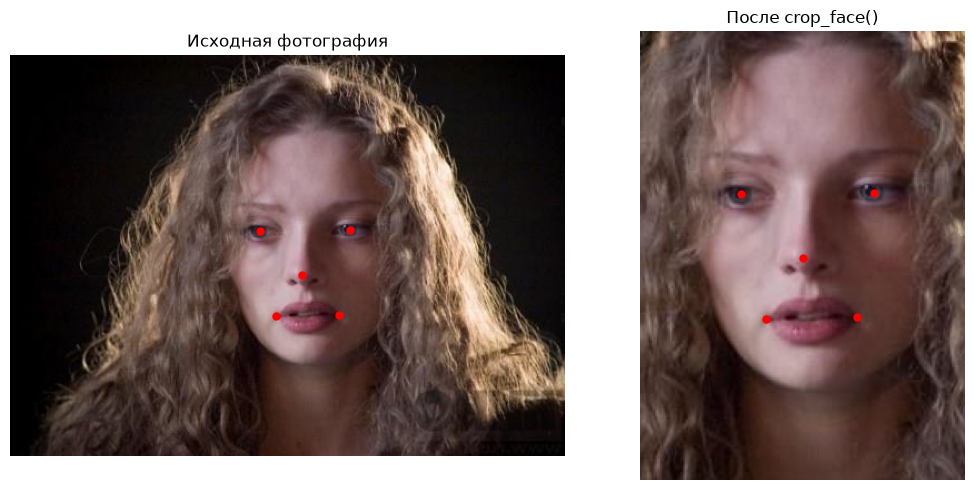

Файл: C:\Users\User\Desktop\face-recognition\data\raw\img_celeba\img_celeba\008286.jpg
Исходный размер: (361, 499, 3) Обрезанный размер: (274, 198, 3)
Размер landmarks: (5, 2)


In [28]:
row = selected_df.iloc[2]
filename = str(row["image_id"])
found_files = list(RAW_DIR.rglob(filename))
if not found_files:
    raise FileNotFoundError(f"Не найден {filename} внутри {RAW_DIR}")
image_path = found_files[0]
image = cv2.imread(str(image_path))
if image is None:
    raise ValueError(f"OpenCV не открыл: {image_path}")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

bbox = row[["x_1", "y_1", "width", "height"]].to_numpy(dtype=np.float32)
landmarks = row[landmark_columns].to_numpy(dtype=np.float32).reshape(5, 2)
cropped, new_landmarks = crop_face(image, bbox, landmarks)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(image)
axes[0].scatter(landmarks[:, 0], landmarks[:, 1], c="red", s=25)
axes[0].set_title("Исходная фотография")
axes[1].imshow(cropped)
axes[1].scatter(new_landmarks[:, 0], new_landmarks[:, 1], c="red", s=25)
axes[1].set_title("После crop_face()")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Файл:", image_path)
print("Исходный размер:", image.shape, "Обрезанный размер:", cropped.shape)
print("Размер landmarks:", new_landmarks.shape)

In [29]:
def resize_face(image, landmarks, size=256):
    old_h, old_w = image.shape[:2]

    scale_x = size/old_w
    scale_y = size/old_h 

    resized_image = cv2.resize(image, (size, size))
    resized_landmarks = landmarks.copy()

    resized_landmarks[:,0] *= scale_x
    resized_landmarks[:,1] *= scale_y 

    return resized_image, resized_landmarks

До resize: (274, 198, 3)
После resize: (256, 256, 3)


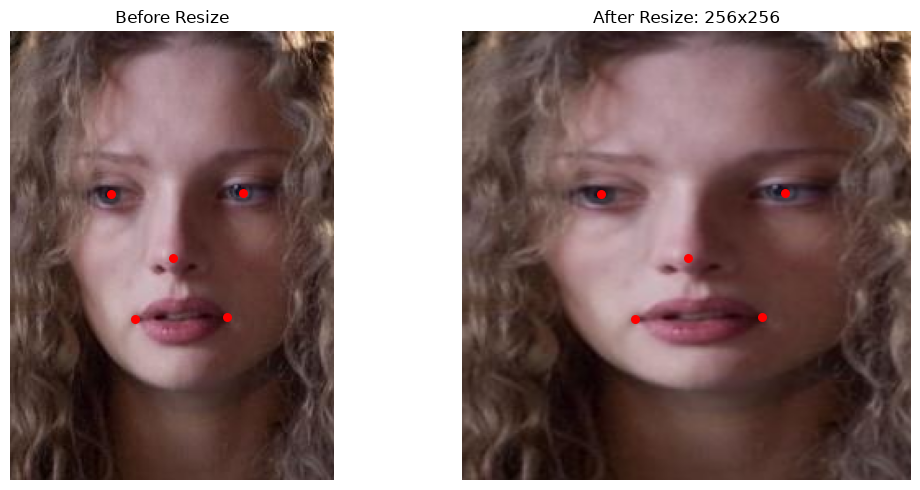

In [30]:
resized_image, resized_landmarks = resize_face(
    cropped,
    new_landmarks,
    size=256
)

print("До resize:", cropped.shape)
print("После resize:", resized_image.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(cropped)
axes[0].scatter(
    new_landmarks[:, 0],
    new_landmarks[:, 1],
    c="red",
    s=30
)
axes[0].set_title("Before Resize")
axes[0].axis("off")

axes[1].imshow(resized_image)
axes[1].scatter(
    resized_landmarks[:, 0],
    resized_landmarks[:, 1],
    c="red",
    s=30
)
axes[1].set_title("After Resize: 256x256")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [31]:
import numpy as np

def create_heatmap(size, landmark, sigma=2):
    """
    Создаёт одну heatmap для одной ключевой точки.

    size: (height, width)
    landmark: (x, y)
    sigma: ширина гауссова пятна
    """
    h, w = size
    x, y = landmark

    xx, yy = np.meshgrid(np.arange(w), np.arange(h))

    heatmap = np.exp(
        -((xx - x)**2 + (yy - y)**2) / (2 * sigma**2)
    )

    return heatmap.astype(np.float32)


def landmarks_to_heatmaps(image_shape, landmarks, sigma=2):
    """
    Преобразует N ключевых точек в N тепловых карт.

    Результат: (N, H, W)
    """
    heatmaps = []

    for x, y in landmarks:
        hm = create_heatmap(
            image_shape,
            (x, y),
            sigma=sigma
        )
        heatmaps.append(hm)

    return np.stack(heatmaps)

Форма heatmaps: (5, 64, 64)


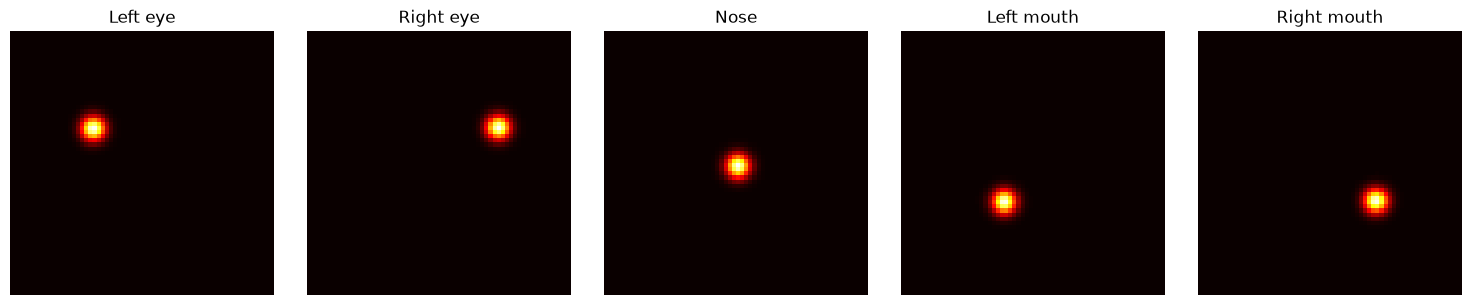

In [32]:
# Переводим координаты с 256x256 на 64x64
heatmap_landmarks = resized_landmarks.copy()

heatmap_landmarks[:, 0] *= 64 / 256
heatmap_landmarks[:, 1] *= 64 / 256

# Создаём пять тепловых карт
heatmaps = landmarks_to_heatmaps(
    (64, 64),
    heatmap_landmarks,
    sigma=2
)

print("Форма heatmaps:", heatmaps.shape)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

names = ["Left eye", "Right eye", "Nose", "Left mouth", "Right mouth"]

for i in range(5):
    axes[i].imshow(heatmaps[i], cmap="hot", vmin=0, vmax=1)
    axes[i].set_title(names[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()